In [ ]:
import praw
import pandas as pd
import datetime as dt

# Reddit API credentials (replace with your values)
reddit = praw.Reddit(
    client_id="xyz",
    client_secret="abc",
    user_agent="tesla_data_scraper"
)

In [11]:
# 2. Define subreddits and keyword
subreddits = ['technology', 'elonmusk', 'teslamotors', 'cars']
keyword = "Cybertruck"
all_posts = []

# 3. Loop through subreddits and collect posts
for sub in subreddits:
    subreddit = reddit.subreddit(sub)
    for submission in subreddit.search(keyword, sort="new", limit=3000):
        all_posts.append({
            "title": submission.title,
            "selftext": submission.selftext,
            "score": submission.score,
            "num_comments": submission.num_comments,
            "created": dt.datetime.fromtimestamp(submission.created_utc),
            "author": str(submission.author),
            "url": submission.url,
            "subreddit": sub
        })

# 4. Create DataFrame
df = pd.DataFrame(all_posts)

# 5. Show number of posts (rows)
print("✅ Total posts collected:", len(df))

✅ Total posts collected: 674


In [12]:
# Save the DataFrame to a CSV file
df.to_csv('tesla_reddit_posts.csv', index=False)

In [7]:
import pandas as pd
df = pd.read_csv("C:/Users/Hassan/Desktop/ffb/internship(Data & Dashboard)/tableauworkspace/Tesla CyberTruck/tesla_reddit_posts.csv")

In [8]:
# Check nulls
df.isnull().sum()

title           0
score           0
num_comments    0
created         0
author          0
url             0
subreddit       0
dtype: int64

In [9]:
df = df.dropna(subset=['title'])  # Drop if either title or selftext is missing

In [10]:
df = df.drop_duplicates(subset=['title'])

In [11]:
df['content'] = df['title']

In [12]:
df.shape

(667, 8)

In [13]:
df.to_csv('tesla.csv', index=False)

3.Preprocessing

In [14]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download NLTK resources
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Hassan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Hassan\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [15]:
def clean_text(text):
    text = re.sub(r"http\S+|www\S+|https\S+", '', text)
    text = re.sub(r'\@\w+|\#', '', text)
    text = text.encode('ascii', 'ignore').decode('utf-8')  # Remove emojis
    text = re.sub(r'[^\w\s]', '', text)  # Remove punctuation                        # Remove extra whitespace
    return text.strip().lower()

In [16]:
df['cleaned_content'] = df['content'].apply(clean_text)

In [17]:
stop_words = set(stopwords.words('english'))
df['cleaned_content'] = df['cleaned_content'].apply(
    lambda x: ' '.join([word for word in x.split() if word not in stop_words])
)

In [18]:
lemmatizer = WordNetLemmatizer()
df['Lemmatized_Text'] = df['cleaned_content'].apply(
    lambda x: ' '.join([lemmatizer.lemmatize(word) for word in x.split()])
)

In [19]:
# Save cleaned data
df.to_csv('C:/Users/Hassan/Desktop/ffb/internship(Data & Dashboard)/tableauworkspace/Tesla CyberTruck/data/cleaned.csv', index=False)
print("✅ Cleaned data saved to 'data/cleaned.csv'")

✅ Cleaned data saved to 'data/cleaned.csv'


4.	Sentiment Analysis

In [24]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
nltk.download('vader_lexicon')
sia = SentimentIntensityAnalyzer()
df['sentiment_score'] = df['Lemmatized_Text'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Classify sentiment
def get_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_label'] = df['sentiment_score'].apply(get_sentiment)

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Hassan\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [25]:
df.to_csv('C:/Users/Hassan/Desktop/ffb/internship(Data & Dashboard)/tableauworkspace/Tesla CyberTruck/data/sentiment_vader.csv', index=False)
print("✅ Sentiment analysis with VADER complete and saved.")

✅ Sentiment analysis with VADER complete and saved.


5.	Keyword Extraction & Topic Modeling

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Assuming your cleaned text is in a column named 'clean_text'
tfidf_vectorizer = TfidfVectorizer(max_df=0.85, max_features=1000, stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(df['cleaned_content'])

# Get feature names (i.e., keywords)
feature_names = tfidf_vectorizer.get_feature_names_out()

# Get keywords per post with non-zero TF-IDF scores
all_keywords = []

for row in tfidf_matrix:
    row_array = row.toarray()[0]
    words = [feature_names[i] for i in range(len(row_array)) if row_array[i] > 0]
    all_keywords.append(', '.join(words))

# Add to DataFrame
df['all_keywords'] = all_keywords


In [32]:
# Save to CSV
df.to_csv('reddit_keywords.csv', index=False)


In [34]:
df['timestamp'] = pd.to_datetime(df['created'], format='%d/%m/%Y %H:%M')

df['date'] = df['timestamp'].dt.date  


In [38]:
from collections import Counter
import pandas as pd

# Flatten all keywords into a list
all_keywords_flat = ', '.join(df['all_keywords']).split(', ')

# Count frequency
keyword_freq = Counter(all_keywords_flat)

# Convert to DataFrame
keyword_df = pd.DataFrame(keyword_freq.items(), columns=['keyword', 'frequency'])

# Save to CSV for Tableau
keyword_df.to_csv('keyword_frequency.csv', index=False)


In [39]:
print(all_keywords_flat)

['cybertruck', 'dramatically', 'fall', 'level', 'sales', 'tesla', 'year', 'burning', 'cybertruck', 'defectively', 'designed', 'dies', 'faces', 'lawsuit', 'man', 'tesla', 'away', 'buy', 'cybertruck', 'desperate', 'disastrous', 'dismal', 'electric', 'launch', 'offer', 'offering', 'people', 'polarizing', 'sales', 'save', 'software', 'tesla', 'tries', 'truck', 'valuable', 'cybertruck', 'ev', 'gmc', 'hummer', 'outsold', 'quarter', 'tesla', 'cybertruck', 'fast', 'flopping', 'supposed', 'teslas', 'truck', '10000', 'cybertruck', 'forced', 'fsd', 'refund', 'tesla', 'brand', 'collapse', 'cybertruck', 'flop', 'teslas', 'worse', 'burning', 'cybertruck', 'died', 'family', 'man', 'tesla', 'texas', 'austin', 'cybertruck', 'factory', 'line', 'tesla', 'crash', 'cybertruck', 'defectively', 'designed', 'disintegrated', 'drivers', 'hot', 'lawsuit', 'literally', 'came', 'cybertruck', 'embody', 'problems', 'teslas', 'cybertrucks', 'dumping', 'fed', 'lot', 'parking', 'tesla', 'unsold', '6000', 'collapse', 'c

In [35]:
df.to_csv('reddit_keywords.csv', index=False)

In [46]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Load your cleaned dataset
df = pd.read_csv("data/reddit_keywords.csv")  # Change this to your actual file path

# Step 1: Create a Document-Term Matrix
vectorizer = CountVectorizer(max_df=0.9, min_df=5, stop_words='english')
doc_term_matrix = vectorizer.fit_transform(df['cleaned_content'])

# Step 2: Apply LDA
lda = LatentDirichletAllocation(n_components=5, random_state=42)  # You can increase components for more categories
lda.fit(doc_term_matrix)

# Step 3: Assign topics
df['topic'] = lda.transform(doc_term_matrix).argmax(axis=1)

# Optional: Add top words for each topic
def get_topics(model, feature_names, n_top_words=10):
    topic_keywords = []
    for topic_idx, topic in enumerate(model.components_):
        top_features = [feature_names[i] for i in topic.argsort()[:-n_top_words - 1:-1]]
        topic_keywords.append(", ".join(top_features))
    return topic_keywords

topics = get_topics(lda, vectorizer.get_feature_names_out())
df['topic_keywords'] = df['topic'].apply(lambda x: topics[x])

# Save final version for Tableau
df.to_csv("dataset_with_topics.csv", index=False)


In [44]:
print(df.columns)

Index(['title', 'score', 'num_comments', 'created', 'author', 'url',
       'subreddit', 'content', 'cleaned_content', 'Lemmatized_Text',
       'Sentiment_VADER', 'sentiment_score', 'sentiment_label', 'all_keywords',
       'timestamp', 'date', 'user_query'],
      dtype='object')


In [45]:
df.to_csv("cleaned_data_with_user_query.csv", index=False)

In [47]:
topic_labels = {
    0: "Charging & Range",
    1: "Design & Support",
    2: "Tests & Performance",
    3: "Elon Musk Impact",
    4: "EV Market Trends"
}

df['topic_label'] = df['topic'].map(topic_labels)


In [48]:
df.to_csv("topic_label.csv", index=False)

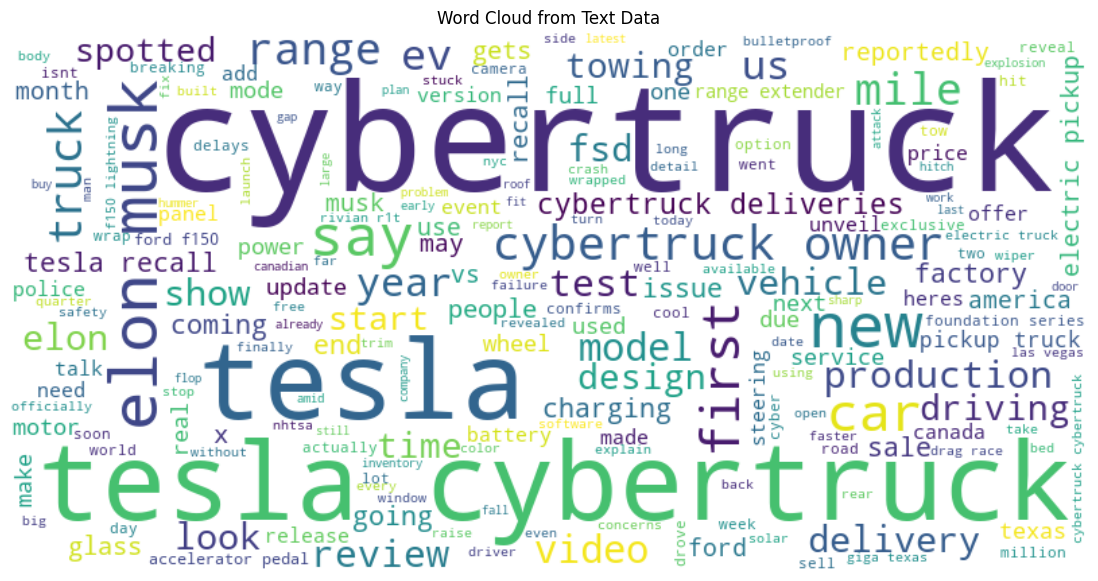

In [51]:
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Load your data
df = pd.read_csv('topic_label.csv')  # Replace with your CSV filename

# Combine all the text from a specific column (e.g., 'clean_text')
text = ' '.join(df['cleaned_content'].dropna().astype(str))

# Create the WordCloud object
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=200,
    colormap='viridis'
).generate(text)

# Plot the WordCloud
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud from Text Data')
plt.show()


In [52]:
print(df.columns)

Index(['title', 'score', 'num_comments', 'created', 'author', 'url',
       'subreddit', 'content', 'cleaned_content', 'Lemmatized_Text',
       'Sentiment_VADER', 'sentiment_score', 'sentiment_label', 'all_keywords',
       'date', 'topic', 'topic_keywords', 'topic_label'],
      dtype='object')
